## Random forest implementatio for bankrupcy prediction

Imports


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix, 
    ConfusionMatrixDisplay, 
    classification_report, 
    recall_score
)

Load and prepare features

In [8]:
sns.set_theme()

choosen_features = [
    'Persistent EPS in the Last Four Seasons', #
    'Total debt/Total net worth', #
    'Non-industry income and expenditure/revenue', #
    'Net Value Growth Rate', #
    'Quick Ratio', #
    'Tax rate (A)', # 
    'Cash/Total Assets', #
    'Operating Gross Margin', #
    'Bankrupt?'
]

data = pd.read_csv('../content/data.csv', sep=',')
data.columns = data.columns.str.strip()
filtered_data = data[choosen_features].copy()

X = filtered_data.drop(columns=['Bankrupt?'])
y = filtered_data['Bankrupt?'] == 1

# Use stratified split so the ~3.2% bankruptcy rate is preserved in both train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=44, stratify=y
)

Winsorization implementation

In [9]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Caps extreme outliers at specified lower and upper quantiles fit on training data."""
    def __init__(self, lower_quantile=0.01, upper_quantile=0.99):
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        self.lower_bounds_ = X_df.quantile(self.lower_quantile)
        self.upper_bounds_ = X_df.quantile(self.upper_quantile)
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        return X_df.clip(lower=self.lower_bounds_, upper=self.upper_bounds_, axis=1).to_numpy()

Pipeline build

In [10]:
pipeline = Pipeline([
    ('winsorizer', Winsorizer(lower_quantile=0.01, upper_quantile=0.99)),
    ('rf', RandomForestClassifier(
        class_weight='balanced', # for class imbalance
        random_state=44,
        n_jobs=-1
    ))
])

Hyperparameters optimalization

In [13]:
param_distributions = {
    'winsorizer__lower_quantile': [0.005, 0.01, 0.02],
    'winsorizer__upper_quantile': [0.98, 0.99, 0.995],
    'rf__n_estimators': [100, 200, 300, 500],
    'rf__max_depth': [4, 6, 8, 10, 12, None],
    'rf__min_samples_split': [2, 5, 10, 20],
    'rf__min_samples_leaf': [1, 2, 5, 10],
    'rf__max_features': ['sqrt', 'log2', 0.5, 0.75],
    'rf__class_weight': ['balanced', 'balanced_subsample']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=44)

search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=50,
    scoring='roc_auc',  # Directly optimizes for catching the 85%+ bankruptcy target
    cv=cv,
    random_state=44,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print(f"Best CV Recall: {search.best_score_:.4f}")
print("Best Parameters:", search.best_params_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best CV Recall: 0.9342
Best Parameters: {'winsorizer__upper_quantile': 0.98, 'winsorizer__lower_quantile': 0.005, 'rf__n_estimators': 200, 'rf__min_samples_split': 5, 'rf__min_samples_leaf': 10, 'rf__max_features': 'sqrt', 'rf__max_depth': 4, 'rf__class_weight': 'balanced'}


Evalueate on Test Data 


Test Set Bankruptcy Detection Rate (Recall): 88.64%

Classification Report:
              precision    recall  f1-score   support

 Solvent (0)       1.00      0.87      0.93      1320
Bankrupt (1)       0.19      0.89      0.31        44

    accuracy                           0.87      1364
   macro avg       0.59      0.88      0.62      1364
weighted avg       0.97      0.87      0.91      1364



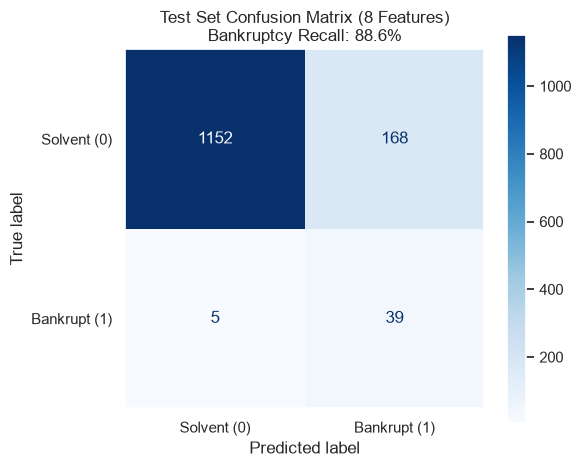

In [16]:
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)

test_recall = recall_score(y_test, y_pred)
print(f"\nTest Set Bankruptcy Detection Rate (Recall): {test_recall:.2%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Solvent (0)', 'Bankrupt (1)']))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Solvent (0)', 'Bankrupt (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
ax.grid(False)
plt.title(f'Test Set Confusion Matrix (8 Features)\nBankruptcy Recall: {test_recall:.1%}')
plt.tight_layout()
plt.show()